# 02 - Demo pipeline lpr-classic

Notebook minh hoạ từng bước của pipeline định vị biển số và tách ký tự bằng xử lý ảnh cổ điển (không học sâu):

`ảnh gốc → tiền xử lý → Sobel-x + Otsu → morph close → ứng viên + NMS → SVM rerank → quad + warp 220×70 → nhị phân → tách ký tự → so với GT`

Chủ file: A (synaamin). Chỉ dùng hàm public trong `src/lpr`, tham số đọc từ `config/default.yaml`, seed cố định.

## 1. Cách chạy

Từ thư mục gốc repo (xem README để biết chi tiết):

```bash
pip install -r requirements.txt && pip install -e .
python scripts/build_subset.py --raw data/raw --out data/ccpd_subset --annotations data/annotations.csv   # tạo data/ccpd_subset
PYTHONPATH=src python experiments/train_hog_svm.py                                                          # tạo models/svm.joblib
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/02_pipeline_demo.ipynb
```

Notebook cần `data/ccpd_subset/` và `models/svm.joblib` (cả hai nằm ngoài git).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 80}}
import os, sys, tempfile, random

# chuyển về gốc repo (tìm lên trên cho tới khi thấy config/default.yaml) để mọi đường dẫn đều tương đối
while not os.path.isfile(os.path.join("config", "default.yaml")):
    parent = os.path.dirname(os.getcwd())
    if parent == os.getcwd():
        raise SystemExit("không tìm thấy gốc repo (config/default.yaml)")
    os.chdir(parent)
sys.path.insert(0, "src")  # chạy được cả khi chưa pip install -e .

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from lpr.config import load_config
from lpr.data.dataset import load_records
from lpr.io_utils import read_image
from lpr.types import DebugSteps
from lpr.preprocess import preprocess, to_gray
from lpr.localize.edge import localize_edge, sobel_x_map, binarize_edges, morph_plate_regions
from lpr.localize.hog_svm import load_model, score_candidates
from lpr.rectify import quad_from_candidate, rectify, corner_error
from lpr.binarize import binarize_plate, ensure_text_white, clean_binary
from lpr.segment import segment
from lpr.evaluate import iou, position_hits, count_match
from lpr.visualize import draw_candidates, draw_char_boxes, save_debug_grid, save_comparison

SEED = 42
random.seed(SEED); np.random.seed(SEED); cv2.setRNGSeed(SEED)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

cfg = load_config("config/default.yaml")
model_path = os.path.join(cfg["paths"]["models"], "svm.joblib")
if not os.path.isfile(model_path):
    raise SystemExit("thiếu models/svm.joblib: chạy `PYTHONPATH=src python experiments/train_hog_svm.py` trước")
svm = load_model(model_path)
records = {r.image_id: r for r in load_records(cfg)}
print("seed:", cfg["seed"], "| rectify:", cfg["rectify"], "| binarize:", cfg["binarize"]["method"])

seed: 42 | rectify: {'plate_size': [220, 70], 'quad_method': 'approxpoly'} | binarize: otsu


## 2. Chọn ảnh test cố định

Bốn ảnh cố định theo `image_id`, đều thuộc tập `test` (không dùng để tune). Cách chọn: quét 10 ảnh đầu mỗi subset của tập test rồi lấy một ca chạy tốt, một ca nghiêng, một ca mờ mà tách ký tự còn nhạy với phương pháp, và một ca thất bại ở bước định vị.

In [2]:
DEMO = {
    "base_0013": "base: ca chuẩn, chạy tốt",
    "tilt_0013": "tilt: biển nghiêng",
    "blur_0013": "blur: ảnh mờ, CCA và projection cho kết quả khác nhau",
    "challenge_0001": "challenge: ca thất bại (định vị sai)",
}
rows = []
for iid, note in DEMO.items():
    r = records[iid]
    assert r.split == "test", iid
    rows.append({"image_id": iid, "subset": r.subset, "split": r.split, "biển": r.text, "ghi chú": note})
pd.DataFrame(rows)

,image_id,subset,split,biển,ghi chú
0,base_0013,base,test,皖A2K050,"base: ca chuẩn, chạy tốt"
1,tilt_0013,tilt,test,皖AN116F,tilt: biển nghiêng
2,blur_0013,blur,test,皖AS999M,"blur: ảnh mờ, CCA và projection cho kết quả kh..."
3,challenge_0001,challenge,test,皖AW558W,challenge: ca thất bại (định vị sai)


## 3. Từng bước trên một ảnh

Mặc định dùng `base_0013`; đổi `IMAGE_ID` sang ảnh khác trong `DEMO` để xem các ca còn lại.

base_0013: ảnh 720x1160, biển GT = '皖A2K050', bbox GT = (264, 517, 448, 586)


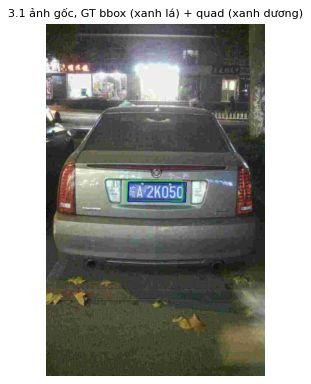

In [3]:
IMAGE_ID = "base_0013"
rec = records[IMAGE_ID]
img = read_image(rec.path)
H, W = img.shape[:2]
print(f"{rec.image_id}: ảnh {W}x{H}, biển GT = {rec.text!r}, bbox GT = {rec.bbox}")

def small(im, width=640):
    s = width / im.shape[1]
    return cv2.resize(im, (width, int(round(im.shape[0] * s))), interpolation=cv2.INTER_AREA) if s < 1 else im

def show(ax, im, title):
    im = small(np.asarray(im))
    ax.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")

def panels(items, cols=3, w=5.2):
    rows = -(-len(items) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(w * cols, w * 0.7 * rows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, (t, im) in zip(axes.ravel(), items): show(ax, im, t)
    plt.tight_layout(); plt.show()

# (3.1) ảnh gốc + bbox GT (xanh lá) + quad GT (xanh dương)
vis = draw_candidates(img, [], gt=rec.bbox)
cv2.polylines(vis, [np.round(rec.quad).astype(np.int32).reshape(-1, 1, 2)], True, (255, 0, 0), 2)
panels([("3.1 ảnh gốc, GT bbox (xanh lá) + quad (xanh dương)", vis)], cols=1, w=7)

### 3.2 Tiền xử lý: resize → xám → CLAHE → bilateral

resize_width=800, scale=1.111, denoise=bilateral


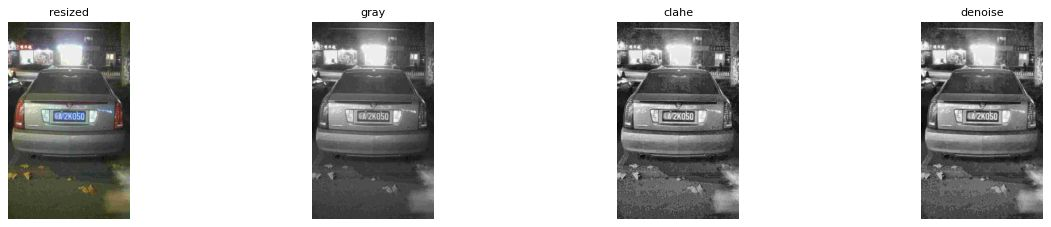

In [4]:
gray, scale, pre = preprocess(img, cfg)
print(f"resize_width={cfg['preprocess']['resize_width']}, scale={scale:.3f}, denoise={cfg['preprocess']['denoise']}")
panels([(k, v) for k, v in pre.images.items()], cols=4, w=4.2)

### 3.3 Sobel-x + Otsu, morph close

Biển có nhiều nét dọc (ký tự) nên Sobel theo x nổi bật vùng biển. Otsu nhị phân hóa bản đồ cạnh, rồi close bằng kernel nằm ngang để nối ký tự thành một khối. Bên dưới là mặt nạ của kernel chính và hai kernel phụ trong `extra_close_kernels` (mỗi kernel sinh ứng viên riêng, sau đó gộp bằng NMS).

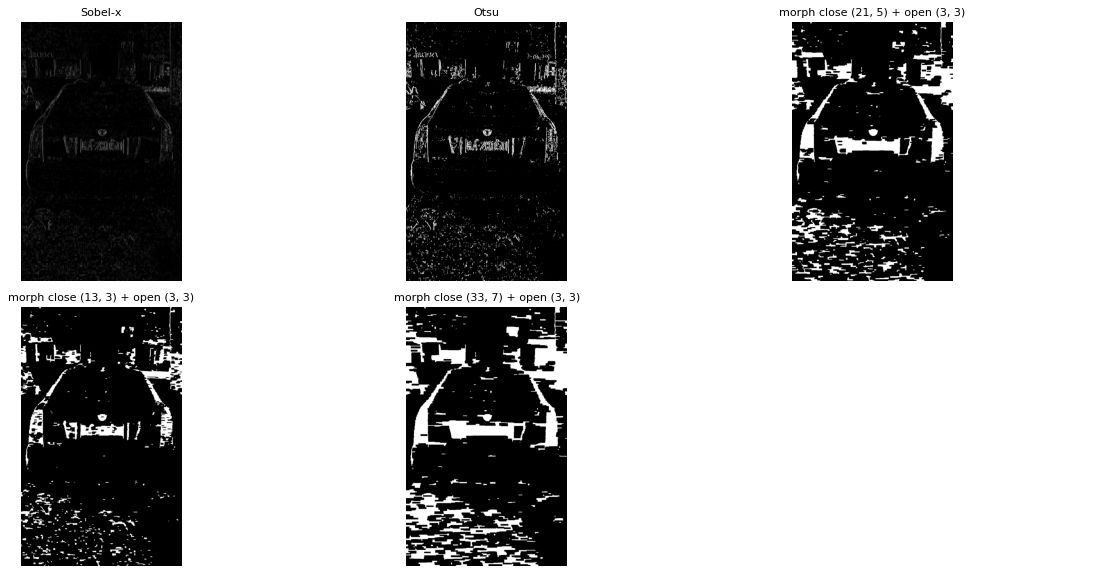

In [5]:
lc = cfg["localize"]
edge = sobel_x_map(gray, lc["sobel_ksize"])
bin_edge = binarize_edges(edge)
items = [("Sobel-x", edge), ("Otsu", bin_edge)]
for k in [lc["close_kernel"]] + list(lc["extra_close_kernels"]):
    items.append((f"morph close {tuple(k)} + open {tuple(lc['open_kernel'])}",
                  morph_plate_regions(bin_edge, tuple(k), tuple(lc["open_kernel"]))))
panels(items, cols=3, w=5.2)

### 3.4 Ứng viên sau lọc hình học + NMS

3 ứng viên (top_k=5, nms_iou=0.5); điểm ở bước này là heuristic


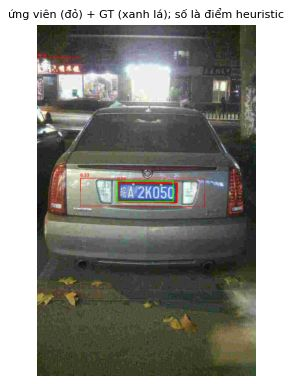

In [6]:
cands, dbg = localize_edge(img, cfg, return_debug=True)
print(f"{len(cands)} ứng viên (top_k={lc['top_k']}, nms_iou={lc['nms_iou']}); điểm ở bước này là heuristic")
panels([("ứng viên (đỏ) + GT (xanh lá); số là điểm heuristic", draw_candidates(img, cands, gt=rec.bbox))], cols=1, w=7)

### 3.5 Chấm lại bằng HOG + SVM (top-5)

,hạng,điểm SVM,bbox,IoU với GT,aspect,fill
0,1,2.022,"(263, 520, 461, 589)",0.854,3.09,0.58
1,2,0.498,"(142, 507, 551, 603)",0.323,4.56,0.43
2,3,-1.365,"(0, 110, 142, 162)",0.000,2.80,0.42


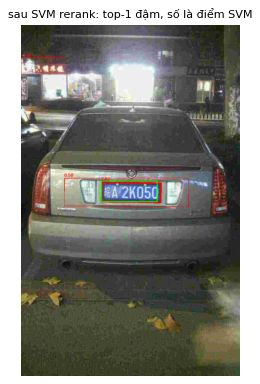

In [7]:
ranked = score_candidates(img, cands, svm, cfg)
tbl = pd.DataFrame([{
    "hạng": i + 1, "điểm SVM": round(c.score, 3), "bbox": c.bbox,
    "IoU với GT": round(iou(c.bbox, rec.bbox), 3),
    "aspect": round(c.features.get("aspect", np.nan), 2),
    "fill": round(c.features.get("fill_ratio", np.nan), 2),
} for i, c in enumerate(ranked[:5])])
display(tbl)
top1 = ranked[0]
panels([("sau SVM rerank: top-1 đậm, số là điểm SVM", draw_candidates(img, ranked, gt=rec.bbox))], cols=1, w=7)

### 3.6 Quad và warp về 220×70

`quad_from_candidate` (mặc định `approxpoly`, lùi về `minAreaRect` nếu thất bại) ước lượng 4 góc. So sánh warp quad của dự đoán, crop bbox, và warp quad GT.

kích thước biển = 220x70, corner error = 5.8 px


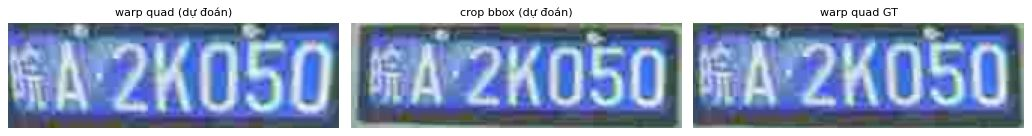

In [8]:
quad = quad_from_candidate(img, top1, cfg["rectify"]["quad_method"])
plate_pred = rectify(img, top1.bbox, quad, "quad", cfg)
plate_bbox = rectify(img, top1.bbox, None, "bbox", cfg)
plate_gt = rectify(img, rec.bbox, rec.quad, "quad", cfg)
ce = corner_error(quad, rec.quad)
print(f"kích thước biển = {plate_pred.shape[1]}x{plate_pred.shape[0]}, corner error = {ce:.1f} px")
fig, axes = plt.subplots(1, 3, figsize=(13, 2.4))
for ax, (t, p) in zip(axes, [("warp quad (dự đoán)", plate_pred), ("crop bbox (dự đoán)", plate_bbox), ("warp quad GT", plate_gt)]):
    show(ax, p, t)
plt.tight_layout(); plt.show()

### 3.7 Nhị phân hóa biển đã nắn

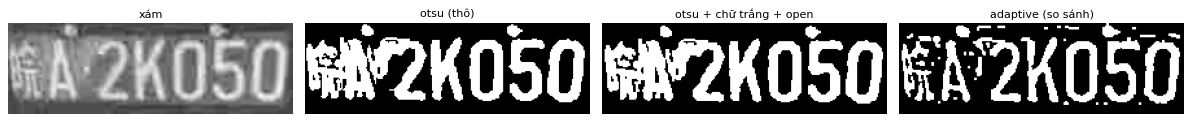

In [9]:
pg = to_gray(plate_pred)
bm = cfg["binarize"]["method"]
raw_bin = binarize_plate(pg, bm, cfg["binarize"].get(bm, {}))
binary = clean_binary(ensure_text_white(raw_bin))
adaptive = clean_binary(ensure_text_white(binarize_plate(pg, "adaptive", cfg["binarize"]["adaptive"])))
fig, axes = plt.subplots(1, 4, figsize=(15, 2.2))
for ax, (t, p) in zip(axes, [("xám", pg), (f"{bm} (thô)", raw_bin), (f"{bm} + chữ trắng + open", binary), ("adaptive (so sánh)", adaptive)]):
    show(ax, p, t)
plt.tight_layout(); plt.show()

### 3.8 Tách ký tự: CCA và projection

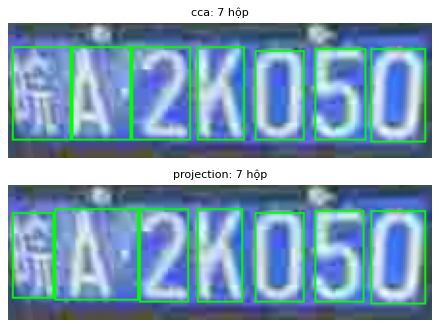

In [10]:
res = {}
fig, axes = plt.subplots(2, 1, figsize=(7, 4.2))
for ax, sm in zip(axes, ["cca", "projection"]):
    boxes = segment(binary, sm, cfg)
    res[sm] = boxes
    show(ax, draw_char_boxes(plate_pred, boxes), f"{sm}: {len(boxes)} hộp")
plt.tight_layout(); plt.show()

### 3.9 So với ground truth

- IoU: giữa bbox top-1 và bbox GT (ngưỡng đạt `evaluate.iou_threshold`).
- Corner error: khoảng cách trung bình 4 góc giữa quad dự đoán và quad GT (pixel ảnh gốc).
- `count_match`: số hộp bằng độ dài chuỗi biển GT. `position`: 7 ô khuôn có hộp trúng (1) hay không (0).

In [11]:
summary = [{
    "image_id": IMAGE_ID, "IoU": round(iou(top1.bbox, rec.bbox), 3),
    "IoU đạt": iou(top1.bbox, rec.bbox) >= cfg["evaluate"]["iou_threshold"],
    "corner error (px)": round(ce, 1), "GT": rec.text,
}]
display(pd.DataFrame(summary))
seg_rows = []
for sm, boxes in res.items():
    hits = position_hits(boxes, cfg)
    seg_rows.append({"method": sm, "số hộp": len(boxes), "kỳ vọng": len(rec.text),
                     "count_match": count_match(boxes, rec.text),
                     "position (7 ô)": "".join("1" if h else "0" for h in hits), "trúng": f"{sum(hits)}/7"})
display(pd.DataFrame(seg_rows))

,image_id,IoU,IoU đạt,corner error (px),GT
0,base_0013,0.854,True,5.8,皖A2K050


,method,số hộp,kỳ vọng,count_match,position (7 ô),trúng
0,cca,7,7,True,1111111,7/7
1,projection,7,7,True,1111111,7/7


## 4. Lưới so sánh 4 ảnh

Chạy cả pipeline cho bốn ảnh cố định rồi ghép bằng `save_debug_grid` / `save_comparison` (ghi ra thư mục tạm, tự xóa sau khi đọc lại để hiển thị). Ca thất bại (`challenge_0001`) cho thấy khi định vị sai thì các bước sau hỏng theo.

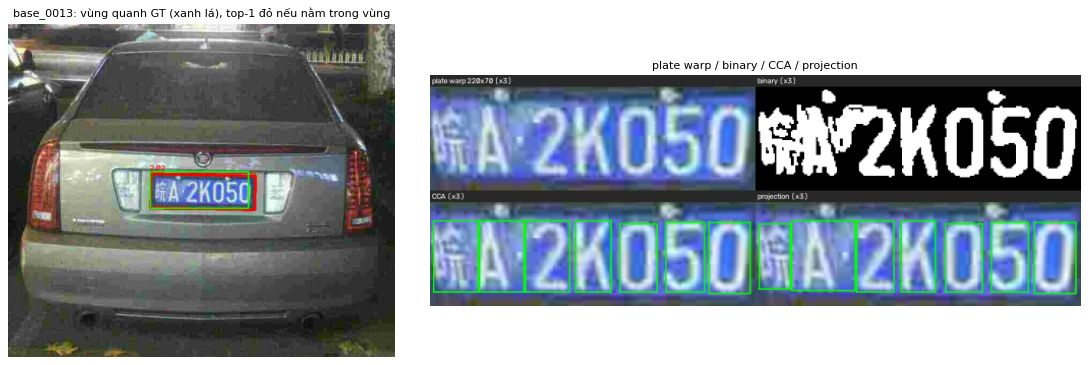

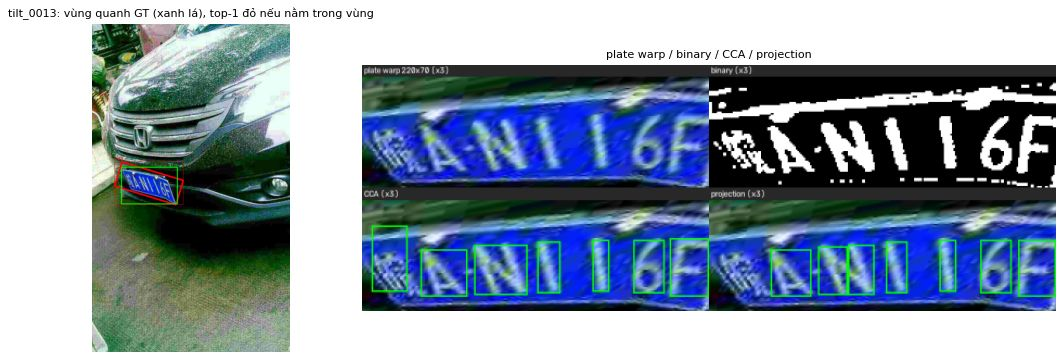

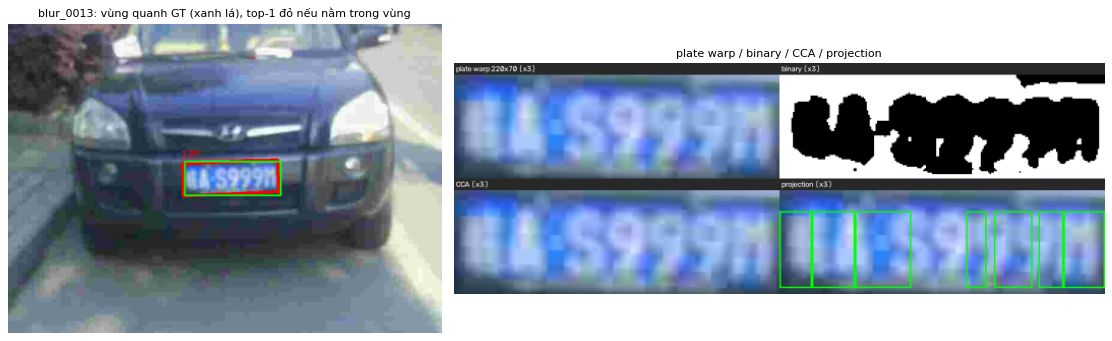

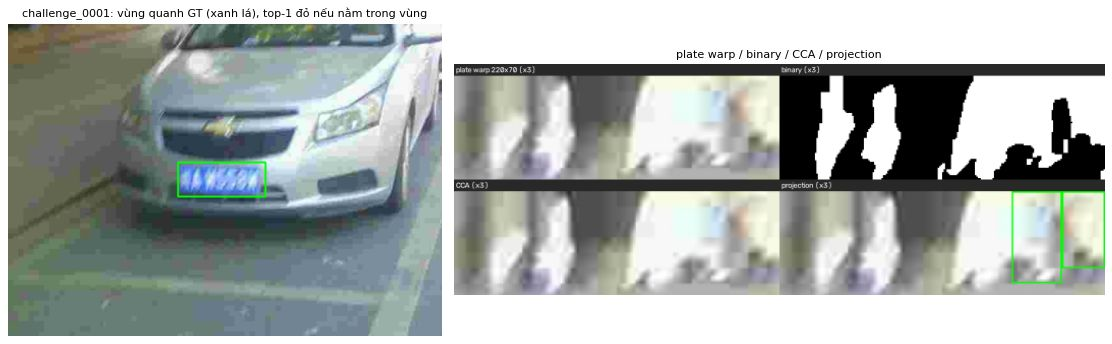

In [12]:
def run_pipeline(iid):
    r = records[iid]; im = read_image(r.path)
    cs = localize_edge(im, cfg)
    rk = score_candidates(im, cs, svm, cfg)
    out = {"rec": r, "img": im, "cands": cs, "ranked": rk}
    if not rk:
        return out
    t = rk[0]; q = quad_from_candidate(im, t, cfg["rectify"]["quad_method"])
    plate = rectify(im, t.bbox, q, "quad", cfg)
    bm_ = cfg["binarize"]["method"]
    b = clean_binary(ensure_text_white(binarize_plate(to_gray(plate), bm_, cfg["binarize"].get(bm_, {}))))
    out.update(top1=t, quad=q, plate=plate, binary=b, corner=corner_error(q, r.quad),
               boxes={m: segment(b, m, cfg) for m in ("cca", "projection")})
    return out

def up(im, f=3):
    return cv2.resize(im, None, fx=f, fy=f, interpolation=cv2.INTER_NEAREST)

def roi(im, boxes, margin=1.0):
    # cắt vùng quanh bbox GT cho lưới gọn (ca định vị sai thì top-1 có thể nằm ngoài vùng); margin theo kích thước bbox
    x1 = min(b[0] for b in boxes); y1 = min(b[1] for b in boxes)
    x2 = max(b[2] for b in boxes); y2 = max(b[3] for b in boxes)
    mx, my = int((x2 - x1) * margin), int((y2 - y1) * margin * 2)
    h, w = im.shape[:2]
    return im[max(0, y1 - my):min(h, y2 + my), max(0, x1 - mx):min(w, x2 + mx)]

runs = {iid: run_pipeline(iid) for iid in DEMO}
for iid, o in runs.items():
    if "plate" not in o:
        print(iid, ": không có ứng viên"); continue
    # ảnh vùng quanh GT cao hơn hẳn các ô còn lại, đưa vào lưới sẽ làm mọi ô cao theo -> hiển thị riêng
    full = draw_candidates(o["img"], o["ranked"][:1], gt=o["rec"].bbox)
    steps = DebugSteps()
    steps.images["plate warp 220x70 (x3)"] = up(o["plate"])
    steps.images["binary (x3)"] = up(o["binary"])
    steps.images["CCA (x3)"] = up(draw_char_boxes(o["plate"], o["boxes"]["cca"]))
    steps.images["projection (x3)"] = up(draw_char_boxes(o["plate"], o["boxes"]["projection"]))
    with tempfile.TemporaryDirectory() as tmp:  # tự xóa khi xong, ảnh đã đọc vào bộ nhớ
        p = os.path.join(tmp, f"{iid}.png")
        save_debug_grid(steps, p, cols=2)  # 4 ô -> lưới 2x2
        g = read_image(p)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
    show(axes[0], roi(full, [o["rec"].bbox], margin=2.0), f"{iid}: vùng quanh GT (xanh lá), top-1 đỏ nếu nằm trong vùng")
    show(axes[1], g, "plate warp / binary / CCA / projection")
    plt.tight_layout(); plt.show()


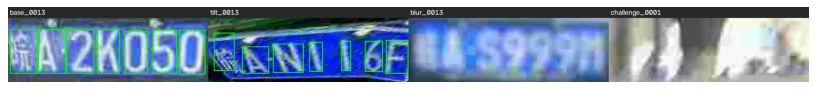

,image_id,subset,GT,số ứng viên,điểm SVM,IoU,corner (px),cca: hộp,cca: count_match,cca: pos,projection: hộp,projection: count_match,projection: pos
0,base_0013,base,皖A2K050,3,2.02,0.85,5.8,7,True,7/7,7,True,7/7
1,tilt_0013,tilt,皖AN116F,3,0.42,0.70,16.1,7,True,6/7,7,True,4/7
2,blur_0013,blur,皖AS999M,2,1.09,0.88,5.9,0,False,0/7,7,True,1/7
3,challenge_0001,challenge,皖AW558W,1,-1.52,0.00,392.7,0,False,0/7,2,False,2/7


In [13]:
# biển đã nắn + hộp CCA của 4 ảnh cạnh nhau (x2)
cmp_imgs = {iid: up(draw_char_boxes(o["plate"], o["boxes"]["cca"]), 2) for iid, o in runs.items() if "plate" in o}
with tempfile.TemporaryDirectory() as tmp:
    p = os.path.join(tmp, "compare.png")
    save_comparison(cmp_imgs, p)
    g = read_image(p)
plt.figure(figsize=(13, 13 * g.shape[0] / g.shape[1]))
plt.imshow(cv2.cvtColor(g, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

rows = []
for iid, o in runs.items():
    r = o["rec"]
    row = {"image_id": iid, "subset": r.subset, "GT": r.text, "số ứng viên": len(o["cands"])}
    if "top1" in o:
        row.update({"điểm SVM": round(o["top1"].score, 2), "IoU": round(iou(o["top1"].bbox, r.bbox), 2),
                    "corner (px)": round(o["corner"], 1)})
        for m, bx in o["boxes"].items():
            row[f"{m}: hộp"] = len(bx); row[f"{m}: count_match"] = count_match(bx, r.text)
            row[f"{m}: pos"] = f"{sum(position_hits(bx, cfg))}/7"
    rows.append(row)
pd.DataFrame(rows)

Lưu ý khi đọc bảng: `blur_0013` cho 7 hộp với projection, nhưng chỉ 1/7 ô khuôn có hộp trúng, nên "7 hộp" (`count_match` = True) chưa có nghĩa là đúng. Cần xem thêm cột `pos`. Với CCA ca này cho 0 hộp.

## 5. Đọc thêm: bảng kết quả thí nghiệm

Thí nghiệm E2 đến E7 do `experiments/run_all.py` sinh ra trong `results/tables/` (thư mục này không nằm trong git). Ô dưới đọc các bảng nếu đã có, nếu chưa thì in lệnh để tạo.

In [14]:
TABLES = {
    "E2 bộ lọc khử nhiễu": ("e2_filters.csv", "--exp filters"),
    "E3 edge vs edge_svm": ("e3_localization.csv", "--exp localization"),
    "E4 crop bbox vs warp quad": ("e4_rectify.csv", "--exp rectify"),
    "E5 otsu vs adaptive": ("e5_binarize.csv", "--exp binarize"),
    "E6 cca vs projection": ("e6_segmentation.csv", "--exp segmentation"),
    "E7 thời gian chạy": ("e7_runtime.csv", "--exp runtime"),
}
tdir = os.path.join(cfg["paths"]["results"], "tables")
for title, (name, flag) in TABLES.items():
    path = os.path.join(tdir, name)
    print(f"== {title} ({name})")
    if os.path.isfile(path):
        display(pd.read_csv(path).head(12))
    else:
        print(f"  chưa có. Tạo bằng: PYTHONPATH=src python experiments/run_all.py {flag}")

== E2 bộ lọc khử nhiễu (e2_filters.csv)
  chưa có. Tạo bằng: PYTHONPATH=src python experiments/run_all.py --exp filters
== E3 edge vs edge_svm (e3_localization.csv)
  chưa có. Tạo bằng: PYTHONPATH=src python experiments/run_all.py --exp localization
== E4 crop bbox vs warp quad (e4_rectify.csv)
  chưa có. Tạo bằng: PYTHONPATH=src python experiments/run_all.py --exp rectify
== E5 otsu vs adaptive (e5_binarize.csv)
  chưa có. Tạo bằng: PYTHONPATH=src python experiments/run_all.py --exp binarize
== E6 cca vs projection (e6_segmentation.csv)
  chưa có. Tạo bằng: PYTHONPATH=src python experiments/run_all.py --exp segmentation
== E7 thời gian chạy (e7_runtime.csv)
  chưa có. Tạo bằng: PYTHONPATH=src python experiments/run_all.py --exp runtime
